# Assignment-focused forecast comparison

## What the assignment actually rewards
From `docs/MATH840_final_project.pdf`:

- **Session 1:** beat daily seasonal naive on RMSE over **all 48 hidden hours**. Skill is model RMSE divided by baseline RMSE; below 1 wins.
- **Final private leaderboard:** the **second 24 hours**, ranked using **0.3 × RMSE rank + 0.3 × MAPE rank + 0.4 × Winkler rank**. We cannot calculate class ranks without other students' hidden results.
- A valid file has exactly 48 timestamps matching `weather_forecast.csv`, forecast, lower_95, and upper_95, with nonnegative lower bounds enclosing the forecast.
- Explain weather usage, validation, intervals, unsuccessful approaches, and LLM use. Use only provided input data; never look up the disguised series' original source.

Our earlier comparisons emphasized pooled RMSE. This run additionally examines day-two metrics and interval quality, and tests whether adapting faster to the recent generation decline helps.

## Targeted candidates
- Timestral-28M using only the latest 7 days (faster adaptation).
- Timestral-28M using 21 days plus known hour-of-day categories.
- Timestral-123M using 21 days and weather.
- Half-strength corrections to the 28M/123M forecasts based on the preceding completed 48-hour block: either level ratio or mean bias, separately for daylight/night.
- Fixed blends with SARIMA, plus the previous Timestral, equal ensemble, SARIMA, and official seasonal-naive baseline.

Corrections never use the target values from the forecast window. They use observed-weather hindcasts for the completed previous block to diagnose model bias retrospectively. The forecast for actual future hours uses the supplied weather forecast. All models run locally, with no external project data.

## Interval policies
Each candidate has three causal interval methods, fitted only on earlier completed windows:

1. Absolute errors, separately for forecast day one and two.
2. Errors scaled by `50 + 0.2 × point forecast`, allowing width to vary with expected generation.
3. Signed scaled errors split by daylight and forecast day, using 2.5th and 97.5th percentiles for asymmetric intervals.

Scale choices are fixed modeling assumptions, not guaranteed optimal settings. Bounds include the point forecast and are clipped at zero. More adaptive intervals may help the Winkler score but nominal 95% does not ensure future 95% coverage.

## Selection and limitations
The same eleven windows select the lowest weather-stress 48-hour RMSE. For that point model, choose the interval with lowest selection Winkler. The latest previously seen audit does not select the model. The selected interval has been tuned on validation, so its reported performance is not an independent test. Repeated searches increase selection optimism. The weather-error scenarios are illustrative, not measured forecast error distributions.

No historical win rate guarantees beating the hidden 48 hours. This report keeps recent failures visible instead of presenting only the winning average.


In [ ]:
# Run from the repository root so data and results paths resolve.
import os, sys
from pathlib import Path
if Path.cwd().name == 'notebooks':
    os.chdir('..')
sys.path.insert(0, str(Path.cwd()))

In [1]:
from pathlib import Path
import json
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
out=Path("results_task")
report=json.loads((out/"run_summary.json").read_text())
winner=report["selected_model"];policy=report["selected_interval"]
best=pd.read_csv(out/"point_model_comparison.csv")
scores=pd.read_csv(out/"all_scores.csv")
pred=pd.read_csv(out/"validation_predictions.csv",parse_dates=["ds"])
print("Session 1 selected:",winner,"with",policy,"intervals")
display(best.set_index("model")[["interval","RMSE","RMSE_ratio","MAPE","Winkler","coverage","wins","windows","win_rate_pct"]].round(3))


Session 1 selected: timestral28_original with absolute_day intervals


,interval,RMSE,RMSE_ratio,MAPE,Winkler,coverage,wins,windows,win_rate_pct
model,,,,,,,,,
timestral28_original,absolute_day,240.792,0.757,142.032,1124.678,0.928,9,11,81.818
timestral28_clock21d,absolute_day,245.291,0.771,145.352,1137.935,0.934,8,11,72.727
timestral123_weather21d,absolute_day,250.817,0.788,189.663,1204.698,0.946,8,11,72.727
timestral123_SARIMA25,absolute_day,253.340,0.796,204.115,1208.023,0.940,9,11,81.818
timestral28_SARIMA50,absolute_day,260.680,0.819,195.939,1162.158,0.947,9,11,81.818
timestral28_original_bias_half,absolute_day,260.917,0.820,174.195,1166.721,0.937,9,11,81.818
timestral28_recent7d,absolute_day,265.621,0.835,151.089,1108.344,0.938,8,11,72.727
equal_mean,absolute_day,265.861,0.836,353.880,1222.930,0.932,9,11,81.818
timestral28_original_level_half,absolute_day,266.781,0.839,175.842,1216.717,0.943,9,11,81.818


## Every selection window, including losses
Intervals do not change RMSE, so each point model appears once. All windows get equal weight in the win count.

label,Oct 03,Oct 05,Oct 07,Oct 09,Oct 11,Oct 13,Oct 15,Oct 17,Oct 19,Oct 21,Oct 23,Oct 25 [audit]
model,,,,,,,,,,,,
timestral28_original,0.94,0.72,0.71,0.76,0.54,1.03,0.70,0.43,0.88,1.18,0.86,1.50
timestral28_clock21d,1.00,0.69,0.75,0.74,0.55,1.01,0.70,0.46,0.89,1.24,0.88,1.54
timestral123_weather21d,1.04,0.76,0.50,1.05,0.60,0.93,0.72,0.57,0.76,1.31,0.82,1.61
timestral123_SARIMA25,0.94,0.87,0.54,1.04,0.63,0.95,0.73,0.63,0.62,1.28,0.82,1.19
timestral28_SARIMA50,0.84,0.96,0.80,0.90,0.63,1.03,0.77,0.61,0.58,1.20,0.85,0.83
timestral28_original_bias_half,0.90,0.85,0.75,0.72,0.72,1.05,0.77,0.51,0.92,1.54,0.76,1.23
timestral28_recent7d,0.98,0.77,0.94,0.75,0.58,1.17,0.77,0.41,0.69,1.39,1.24,0.95
equal_mean,0.91,0.99,0.76,0.88,0.60,1.05,0.75,0.66,0.72,1.00,1.20,1.43
timestral28_original_level_half,0.90,0.85,0.75,0.82,0.74,1.05,0.74,0.56,0.90,1.66,0.76,1.06


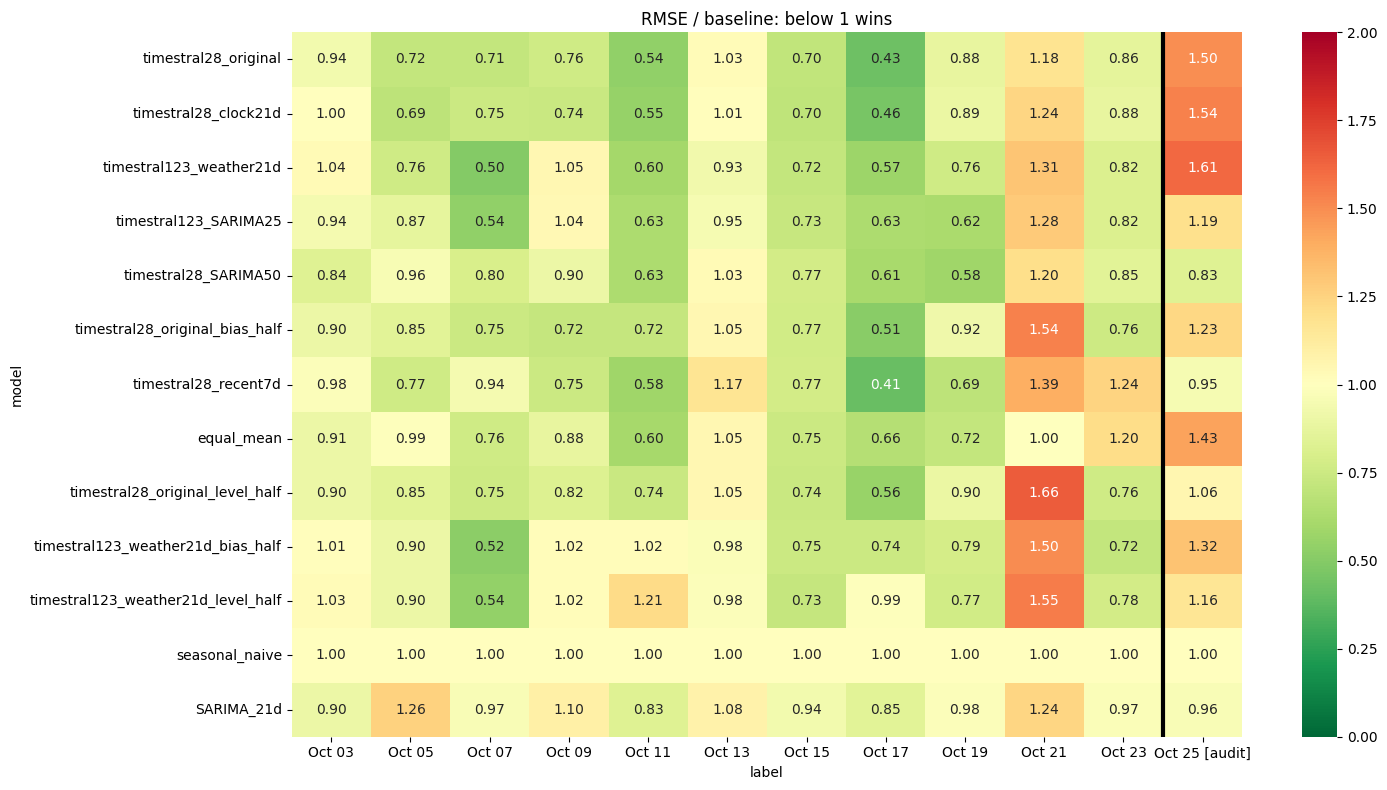

In [2]:
rows=[]
for _,choice in best.iterrows():
    g=pred[(pred.model==choice.model)&(pred.interval==choice.interval)&(pred.scenario=="weather_stress")]
    for (phase,fold),part in g.groupby(["phase","fold"]):
        base=pred[(pred.model=="seasonal_naive")&(pred.scenario=="weather_stress")&(pred.fold==fold)]
        rmse=np.sqrt(np.mean((part.actual-part.forecast)**2))
        base_rmse=np.sqrt(np.mean((base.actual-base.forecast)**2))
        rows.append(dict(model=choice.model,phase=phase,fold=fold,start=part.ds.min(),RMSE=rmse,baseline_RMSE=base_rmse,ratio=rmse/base_rmse))
w=pd.DataFrame(rows)
w["label"]=w.start.dt.strftime("%b %d")+np.where(w.phase.eq("selection"),""," [audit]")
labels=w.sort_values("start").label.drop_duplicates().tolist()
ratios=w.pivot(index="model",columns="label",values="ratio").reindex(index=best.model,columns=labels)
display(ratios.round(2))
w.to_csv(out/"window_comparison.csv",index=False)
fig,ax=plt.subplots(figsize=(15,8))
sns.heatmap(ratios,annot=True,fmt=".2f",cmap="RdYlGn_r",center=1,vmin=0,vmax=max(2,float(ratios.max().max())),ax=ax)
ax.axvline(11,color="black",lw=3);ax.set_title("RMSE / baseline: below 1 wins")
plt.tight_layout();fig.savefig(out/"window_comparison.png",dpi=150,bbox_inches="tight");plt.show()


## Interval comparison for the selected point model
Choose interval by selection Winkler, then inspect coverage. Narrower intervals are not automatically better; misses are heavily penalized.

In [3]:
g=scores[(scores.model==winner)&(scores.scenario=="weather_stress")&(scores.phase=="selection")&(scores.period=="full_48h")]
display(g.set_index("interval")[["RMSE","Winkler","Winkler_ratio","coverage","mean_width"]].round(3))


,RMSE,Winkler,Winkler_ratio,coverage,mean_width
interval,,,,,
absolute_day,240.792,1124.678,0.498,0.928,807.063
scaled_daynight,240.792,1250.787,0.554,0.882,812.187
scaled_symmetric,240.792,1543.945,0.684,0.902,950.302


## Day two: the private-leaderboard horizon
These are validation metrics, not the hidden class ranks. Rows use the interval selected on full-48-hour validation for each model; no audit-based selection occurs.

In [4]:
day2=scores[(scores.scenario=="weather_stress")&(scores.phase=="selection")&(scores.period=="day_two")]
day2=day2.merge(best[["model","interval"]],on=["model","interval"],validate="one_to_one")
display(day2.sort_values("RMSE").set_index("model")[["interval","RMSE","RMSE_ratio","MAPE","MAPE_ratio","Winkler","Winkler_ratio","coverage"]].round(3))


,interval,RMSE,RMSE_ratio,MAPE,MAPE_ratio,Winkler,Winkler_ratio,coverage
model,,,,,,,,
timestral28_original,absolute_day,260.659,0.746,168.127,0.572,1142.904,0.483,0.929
timestral28_clock21d,absolute_day,267.369,0.765,172.729,0.588,1145.863,0.484,0.939
timestral123_weather21d,absolute_day,273.417,0.782,205.734,0.700,1297.601,0.548,0.943
equal_mean,absolute_day,278.737,0.798,240.095,0.817,1286.290,0.543,0.902
timestral123_SARIMA25,absolute_day,281.819,0.806,217.046,0.738,1353.635,0.572,0.928
timestral28_original_bias_half,absolute_day,285.504,0.817,192.622,0.655,1244.907,0.526,0.937
timestral28_original_level_half,absolute_day,294.679,0.843,201.320,0.685,1283.998,0.542,0.941
timestral28_SARIMA50,absolute_day,294.727,0.843,210.357,0.715,1268.866,0.536,0.932
timestral28_recent7d,absolute_day,301.442,0.862,174.360,0.593,1248.748,0.528,0.918


## Previously seen latest audit
This is the window where recent models often failed. Report it even if the selected average winner loses here.

In [5]:
audit=scores[(scores.scenario=="weather_stress")&(scores.phase=="last_window_audit")&(scores.period=="full_48h")]
audit=audit.merge(best[["model","interval"]],on=["model","interval"],validate="one_to_one")
display(audit.sort_values("RMSE").set_index("model")[["RMSE","RMSE_ratio","MAPE","Winkler","coverage"]].round(3))


,RMSE,RMSE_ratio,MAPE,Winkler,coverage
model,,,,,
timestral28_SARIMA50,100.370,0.834,44.996,792.380,1.000
timestral28_recent7d,114.685,0.953,56.457,794.247,1.000
SARIMA_21d,116.108,0.964,38.789,916.614,1.000
seasonal_naive,120.404,1.000,51.088,568.464,1.000
timestral28_original_level_half,127.660,1.060,45.806,782.513,0.993
timestral123_weather21d_level_half,140.098,1.164,67.905,879.330,1.000
timestral123_SARIMA25,143.751,1.194,71.063,805.540,1.000
timestral28_original_bias_half,148.508,1.233,50.999,800.927,0.986
timestral123_weather21d_bias_half,158.877,1.320,74.840,874.533,0.986


## Forecast and submission

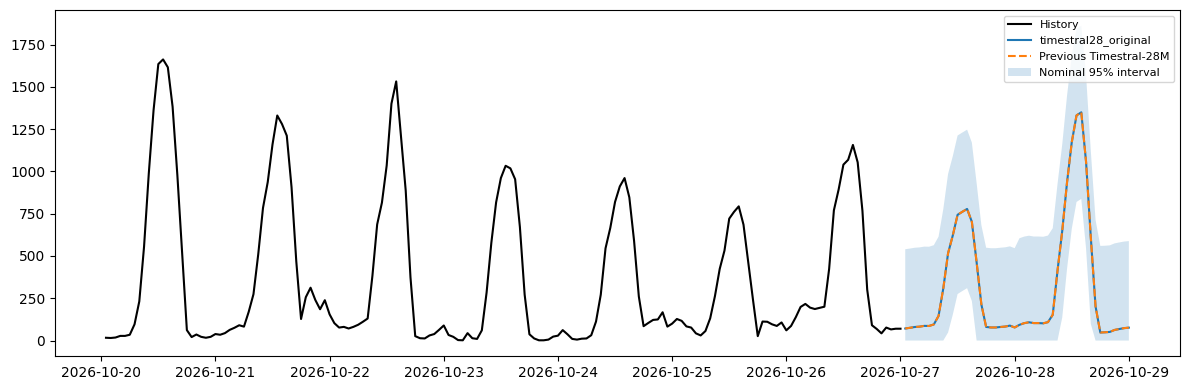

,ds,forecast,lower_95,upper_95
0,2026-10-27 01:00:00,71.151276,0.0,539.670837
1,2026-10-27 02:00:00,75.421750,0.0,543.941284
2,2026-10-27 03:00:00,80.062530,0.0,548.582092
3,2026-10-27 04:00:00,82.007140,0.0,550.526733
4,2026-10-27 05:00:00,86.690430,0.0,555.209961


In [6]:
data=pd.read_csv("train.csv",parse_dates=["ds"])
sub=pd.read_csv(out/"selected_model_forecast.csv",parse_dates=["ds"])
previous=pd.read_csv("results_timestral/selected_model_forecast.csv",parse_dates=["ds"])
fig,ax=plt.subplots(figsize=(12,4))
ax.plot(data.ds.iloc[-168:],data.y.iloc[-168:],color="black",label="History")
ax.plot(sub.ds,sub.forecast,label=winner)
ax.plot(previous.ds,previous.forecast,linestyle="--",label="Previous Timestral-28M")
ax.fill_between(sub.ds,sub.lower_95,sub.upper_95,alpha=.2,label="Nominal 95% interval")
ax.legend(fontsize=8);plt.tight_layout();fig.savefig(out/"forecast.png",dpi=150,bbox_inches="tight");plt.show()
display(sub.head())


In [7]:
SURNAME=""  # Set this to produce the required Moodle filename.
if SURNAME.strip():
    assert not any(c in SURNAME for c in "/\\")
    filename=f"{SURNAME.strip().upper()}_project.csv"
    pd.read_csv(out/"selected_model_forecast.csv").to_csv(filename,index=False)
    print("Saved",filename)
else:
    print("Set SURNAME before saving the Moodle filename. No upload is performed.")


Set SURNAME before saving the Moodle filename. No upload is performed.
